# Milestone 4 - Benchmarking semantic hallucinations

Every claim is tested against **structural controls** (shuffled, frequency-random, uniform-random and Markov-generated inscriptions). The full write-up is `reports/M4_REPORT.md`; this notebook loads the saved results.

*Regenerate:* the M4 block of `run_all.sh`.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
for p in ("src", "src/m3_masking", "src/m4_guardrails", "src/m2_markov", "src/m1_vision"):
    sys.path.insert(0, str(ROOT / p))
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 60)
def wilson(k, n, z=1.96):
    p = k / n; c = (p + z*z/(2*n)) / (1 + z*z/n); h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
    return c - h, c + h

## E1. Perplexity vs noise baselines (medians with bootstrap 95% CIs)

,Transformer,bigram
real,19.6 [16.5-26.9],25.2 [18.6-34.0]
shuffled,224.3 [190.1-257.6],306.2 [254.1-383.3]
markov,54.2 [47.7-67.8],24.7 [20.3-30.8]
freq_random,504.1 [433.1-591.4],496.8 [431.2-573.8]
uniform_random,2995.2 [2655.0-3570.9],3890.9 [3540.6-4296.1]


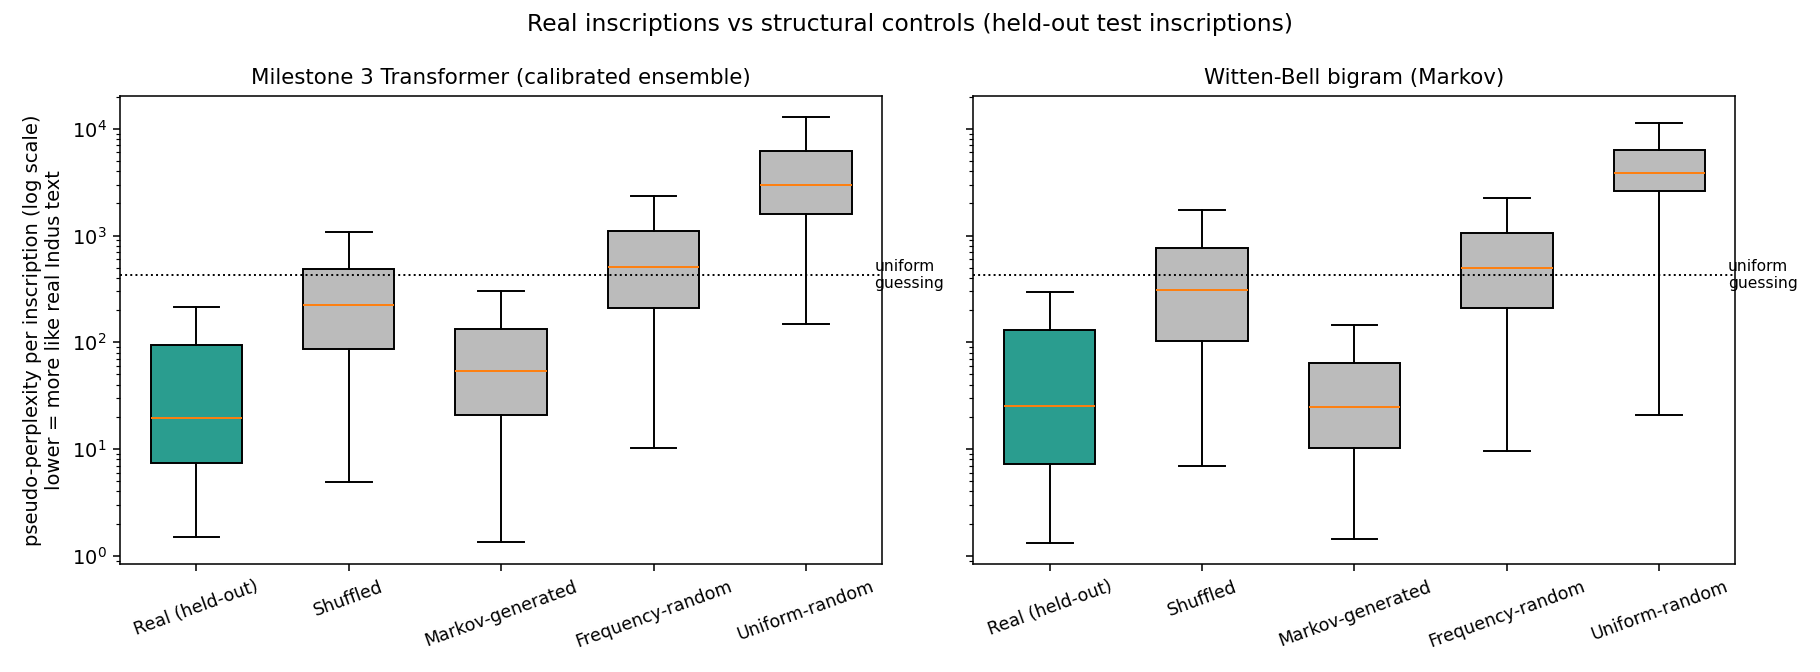

In [2]:
s = json.load(open(ROOT / "reports/m4/perplexity_summary.json"))
display(pd.DataFrame({k: {"Transformer": f"{v['median_ppl_transformer']:.1f} [{v['median_ppl_transformer_ci95'][0]:.1f}-{v['median_ppl_transformer_ci95'][1]:.1f}]",
                          "bigram": f"{v['median_ppl_bigram']:.1f} [{v['median_ppl_bigram_ci95'][0]:.1f}-{v['median_ppl_bigram_ci95'][1]:.1f}]"} for k, v in s.items()}).T)
display(Image(filename=str(ROOT / "reports/m4/perplexity_vs_noise.png"), width=900))

## E2. Confidence scoring against controls

In [3]:
display(pd.DataFrame({k: v["confidence"] for k, v in s.items()}).T)

,n_predictions,share_high,accuracy_when_high,top1
real,1267.0,0.232044,0.751701,0.341752
shuffled,1267.0,0.100237,0.165354,0.081294
markov,1312.0,0.182165,0.531381,0.237043
freq_random,1312.0,0.093750,0.056911,0.029726
uniform_random,1312.0,0.078506,0.000000,0.003049


## E3. Naive Bayes guardrail (5-fold CV) and the perplexity guardrail

In [4]:
nb_ = json.load(open(ROOT / "reports/m4/nb_guardrail.json"))
display(pd.DataFrame({k: {"accuracy": round(v["accuracy"], 3), "AUC": round(v["auc"], 3), "AUC sd": round(v["auc_sd"], 3)} for k, v in nb_.items()}).T)
f7 = json.load(open(ROOT / "reports/m4/f7_guardrail_on_m1.json"))
display(pd.DataFrame({k: {"flag rate": f"{v['flag_rate']:.1%}", "flag 95% CI": [round(x, 3) for x in v["flag_rate_ci95"]], "AUC": v["auc_vs_real"], "AUC 95% CI": v["auc_ci95"]} for k, v in f7["calibration_on_test"].items()}).T)

,accuracy,AUC,AUC sd
shuffled,0.760,0.850,0.012
markov,0.502,0.506,0.011
freq_random,0.801,0.895,0.012
uniform_random,0.927,0.980,0.004


,flag rate,flag 95% CI,AUC,AUC 95% CI
real,6.2%,"[0.04, 0.094]",None,None
shuffled,21.8%,"[0.175, 0.267]",0.80929,"[0.7751216214791702, 0.8437348467279474]"
freq_random,44.5%,"[0.39, 0.501]",0.88532,"[0.8573839918198686, 0.9116901564344746]"
uniform_random,93.8%,"[0.906, 0.96]",0.978316,"[0.9659710216731321, 0.9884152576319784]"
markov,8.1%,"[0.056, 0.117]",0.633275,"[0.587096395893068, 0.6747796846011133]"


## E4. Synthetic corpus vs real inscriptions (numbering-free)

,real (M3 corpus),synthetic
mean_length,4.118058,7.527200
distinct_signs,686.000000,170.000000
top10_share,0.314127,0.526889
adjacent_repeat_rate,0.003861,0.255485
unigram_entropy_bits,7.052815,5.365082
conditional_entropy_bits,3.606982,2.467459


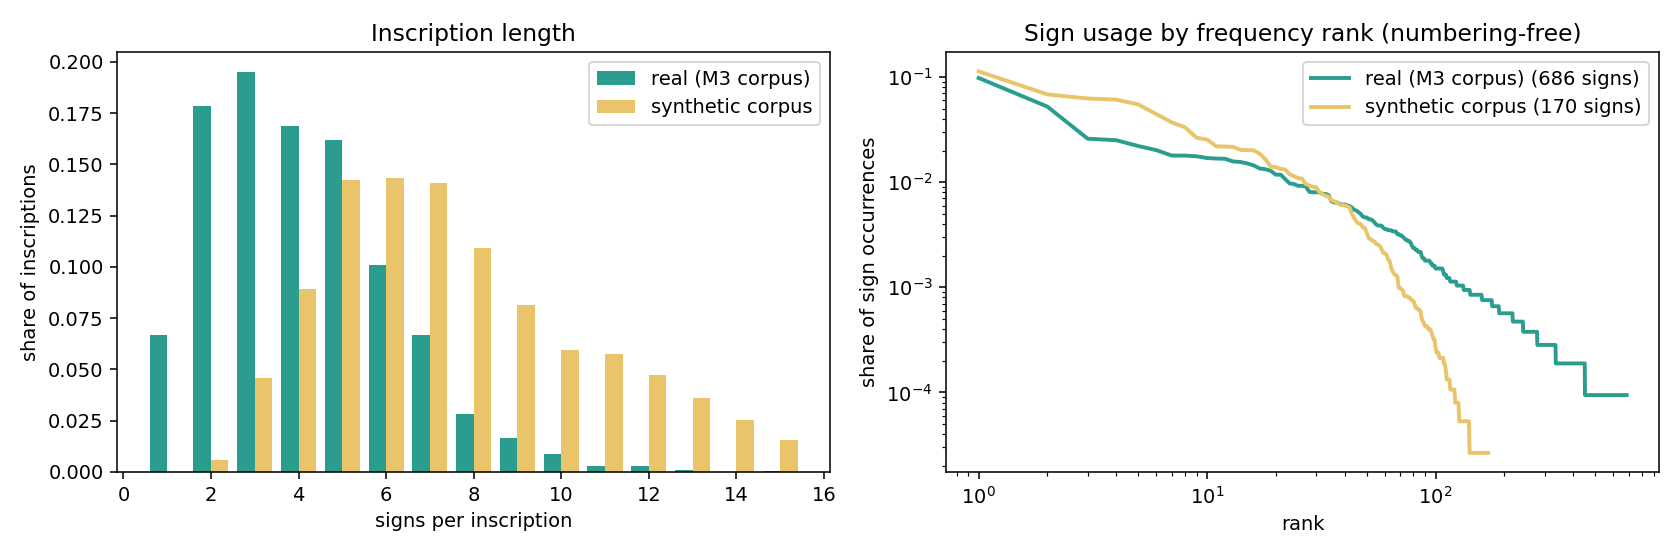

In [5]:
sc_ = json.load(open(ROOT / "reports/m4/synthetic_check.json"))
keys = ["mean_length", "distinct_signs", "top10_share", "adjacent_repeat_rate", "unigram_entropy_bits", "conditional_entropy_bits"]
display(pd.DataFrame({"real (M3 corpus)": [sc_["real_m3_corpus"][k] for k in keys], "synthetic": [sc_["synthetic"][k] for k in keys]}, index=keys))
display(Image(filename=str(ROOT / "reports/m4/synthetic_vs_real.png"), width=900))

## E5. A proposed reading (the Sanskrit columns) against structural controls

In [6]:
print(json.dumps({k: v for k, v in json.load(open(ROOT / "reports/m4/f5_reading_test.json")).items() if k != "T3_freedom_per_sign"}, indent=1))

{
 "T1_consistency": {
  "inscriptions_with_own_reading": 1763,
  "distinct_texts": 1749,
  "texts_with_conflicting_readings": 4
 },
 "T2_naive_bayes_phonetic_anchoring": {
  "n_inscriptions": 1666,
  "majority_baseline": 0.20284697508896798,
  "acc_reading_initial_sign": 0.708277139414864,
  "acc_reading_final_sign": 0.21788854722986456,
  "acc_random_sign": 0.22689575803348258,
  "acc_shuffled_readings_mean": 0.1796787955620291,
  "acc_shuffled_readings_p95": 0.192066677455899,
  "p_value_vs_shuffled": 0.004975124378109453
 }
}


## E6. Error propagation from Milestone 1

,strength,direction,kl,m3_top1,flag
0,0.0,0.895,0.000,0.342,0.062
1,0.1,0.870,0.104,0.318,0.114
2,0.2,0.833,0.211,0.285,0.171
3,0.3,0.799,0.305,0.235,0.261
4,0.4,0.753,0.369,0.227,0.318
5,0.5,0.726,0.459,0.195,0.391
6,0.6,0.684,0.529,0.172,0.441
7,0.8,0.596,0.688,0.132,0.611
8,1.0,0.538,0.814,0.079,0.699


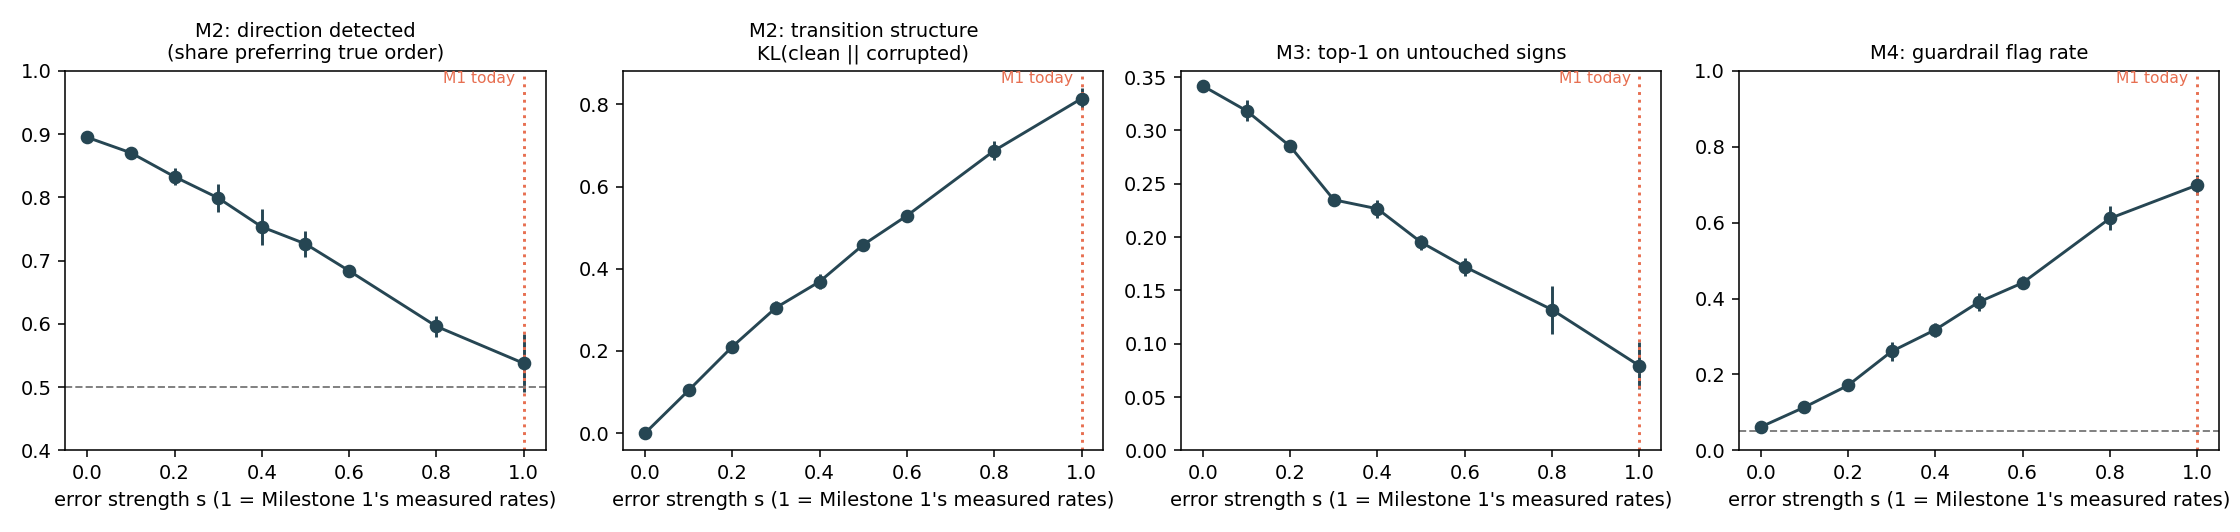

In [7]:
f6 = json.load(open(ROOT / "reports/m4/f6_error_propagation.json"))
display(pd.DataFrame(f6["rows"])[["strength", "direction", "kl", "m3_top1", "flag"]].round(3))
display(Image(filename=str(ROOT / "reports/m4/f6_error_propagation.png"), width=950))

## E7. The guardrail on Milestone 1's real output

{'m1': {'strips': 77, 'signs': 312, 'unmapped_signs': 57, 'ambiguous_mappings': 79, 'strips_scored': 54}, 'm1_top1': {'median_pppl': 1453.7383204118141, 'flag_rate': 0.7407407407407407, 'n': 54}, 'm1_reranked_by_m3': {'median_pppl': 378.1383123147566, 'flag_rate': 0.35185185185185186, 'signs_changed': 158}}


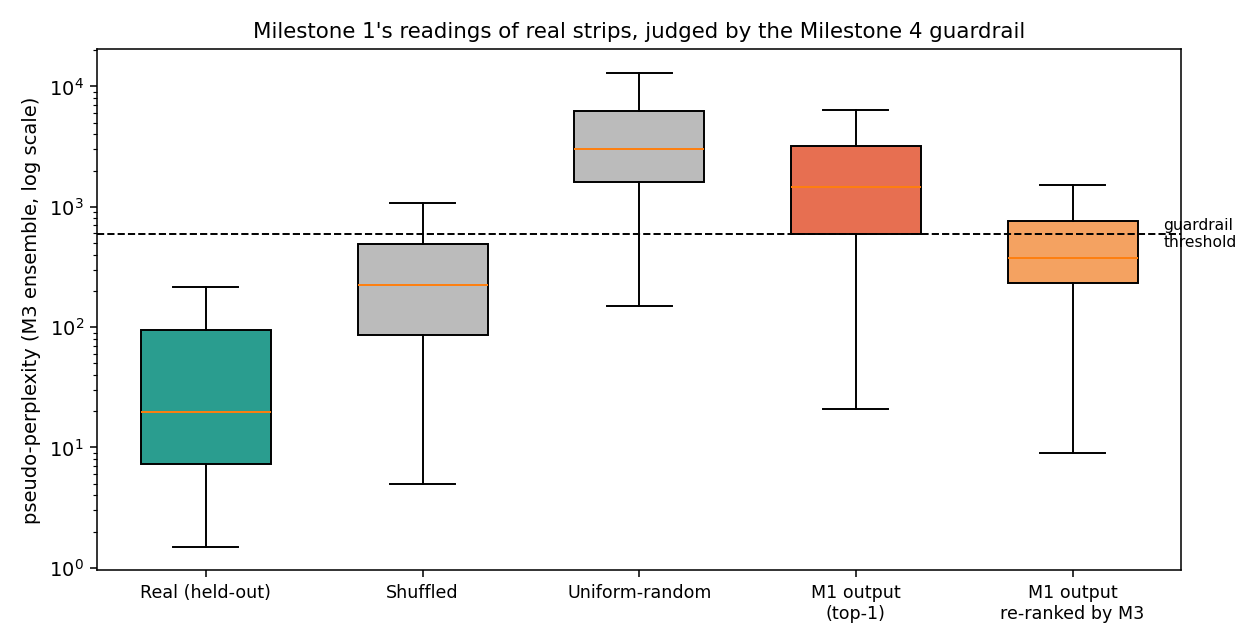

In [8]:
print({k: f7[k] for k in ("m1", "m1_top1", "m1_reranked_by_m3")})
display(Image(filename=str(ROOT / "reports/m4/f7_guardrail_on_m1.png"), width=800))

## E8. Generation (the professor's request)

In [9]:
display(pd.DataFrame(json.load(open(ROOT / "reports/m4/f8_generation.json"))["results"]).T)

,n,median_pppl,guardrail_flag_rate,mean_length,distinct_signs,top_sign_share,adjacent_repeat_rate,copies_of_training_inscriptions,distinct_outputs,nb_auc_vs_real
real (held-out test),308.0,19.622641,0.061688,4.594156,255.0,0.099647,0.015357,0.000,308.0,NaN
markov,1000.0,38.274207,0.056883,4.405000,355.0,0.105335,0.007048,0.161,915.0,0.557880
gibbs (M3),1000.0,18.237568,0.026166,4.405000,361.0,0.084222,0.013803,0.230,927.0,0.663357
hellosindh synthetic (numbering-free stats only),NaN,NaN,NaN,7.527200,170.0,0.113402,0.255485,NaN,NaN,NaN


## The integrated engine: synthetic vs real input

synthetic strips: {'detection': {'count_exact': 0.8, 'mean_abs_count_error': 0.29, 'signs_true': 412, 'signs_detected': 435}, 'recognition_on_count_matched': {'images': 80, 'signs': 340, 'top1': 0.8794117647058823, 'top5': 0.9676470588235294, 'exact_sequence': 0.7}, 'm4_flag_rate': {'image_route': 0.20202020202020202, 'typed_route': 0.09}}
real strips     : {'strips': 77, 'scored': 54, 'verdicts': {'flagged: noise-like': 40, 'not enough readable signs (need >= 2)': 23, 'consistent with real inscriptions': 14}, 'flag_rate': 0.7407407407407407}


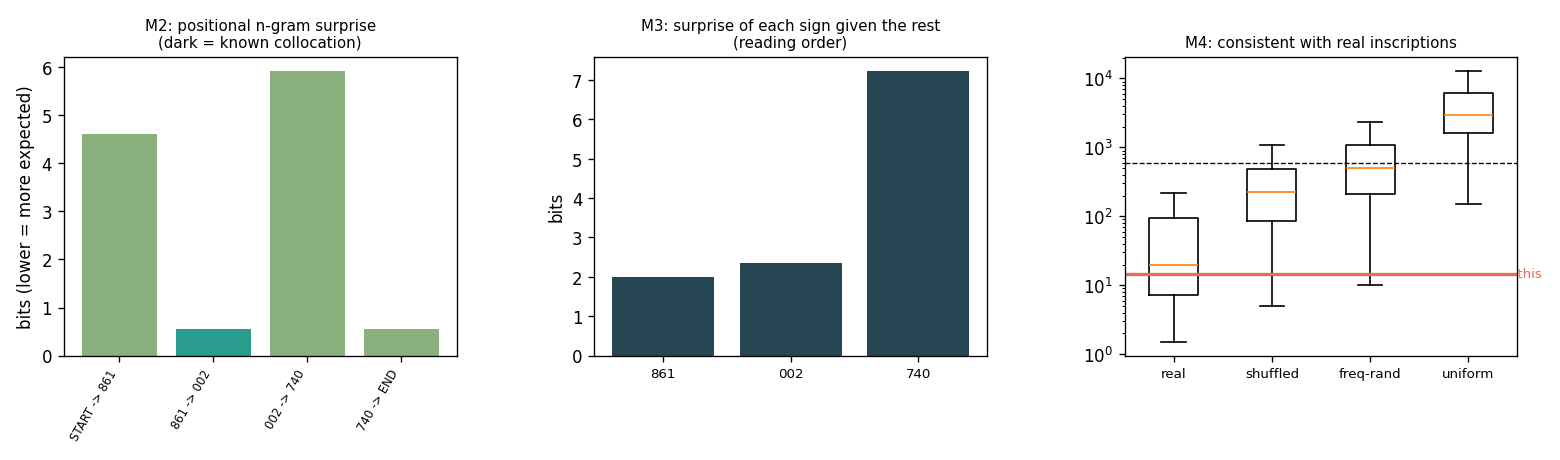

In [10]:
a = json.load(open(ROOT / "reports/engine/synthetic_eval.json")); b = json.load(open(ROOT / "reports/engine/real_eval.json"))
print("synthetic strips:", {k: a[k] for k in ("detection", "recognition_on_count_matched", "m4_flag_rate")})
print("real strips     :", {k: b[k] for k in ("strips", "scored", "verdicts", "flag_rate")})
display(Image(filename=str(ROOT / "reports/engine/demo_typed/panels.png"), width=950))

## E8b. New inscriptions: novelty filter, rendered and read back (`src/engine/generate_and_read.py`)

,copy,near_copy,novel,accepted_novel_and_passes,median_pppl_accepted
markov,0.161,0.322,0.517,0.499,45.877
gibbs (M3),0.230,0.312,0.458,0.451,27.175


{'images': 60, 'count_exact': 0.9, 'sign_top1_on_count_matched': 0.911, 'exact_sequence_on_count_matched': 0.667, 'wells_identical_on_count_matched': 0.37, 'read_back_passes_guardrail': 0.983, 'read_back_passes_guardrail_when_exact': 1.0, 'read_back_passes_guardrail_when_wrong': 0.958}


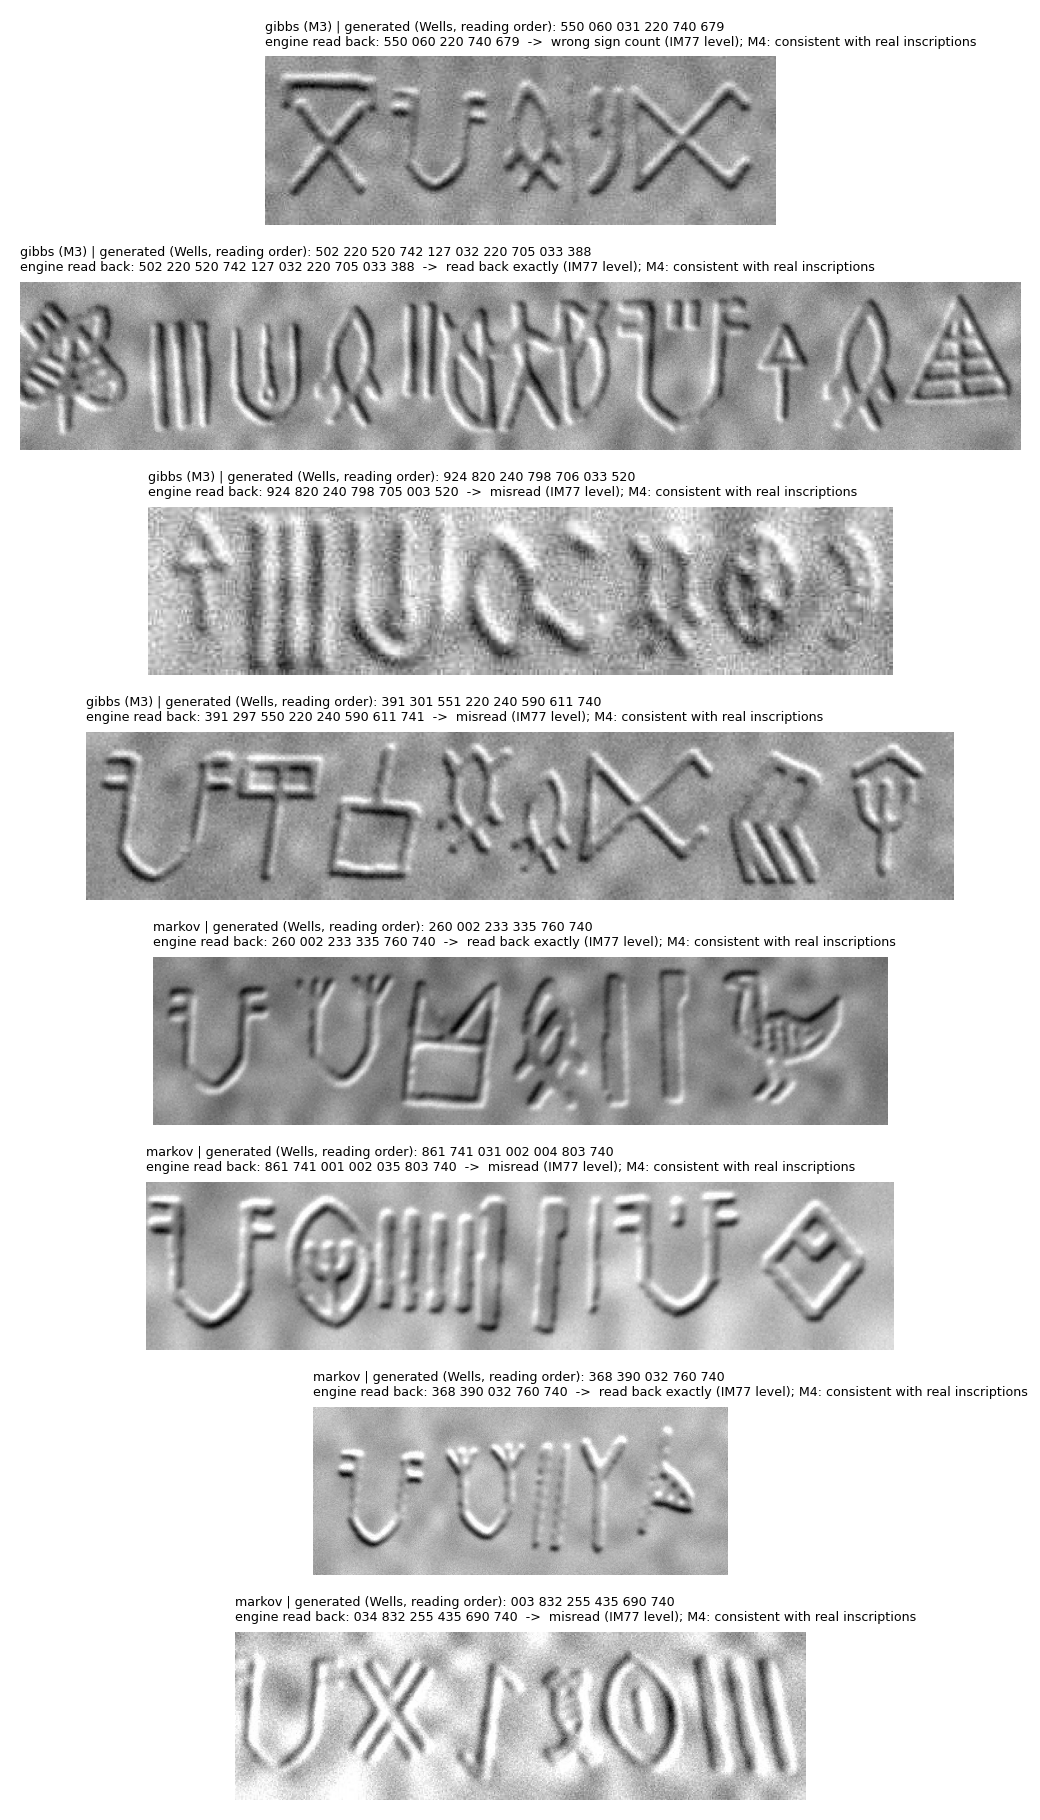

In [11]:
g = json.load(open(ROOT / "reports/engine/generated_roundtrip.json"))
display(pd.DataFrame(g["generation"]).T[["copy", "near_copy", "novel", "accepted_novel_and_passes", "median_pppl_accepted"]].round(3))
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in g["round_trip"].items() if k != "note_wells"})
display(Image(filename=str(ROOT / "reports/engine/generated_gallery.png"), width=800))